In [4]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import os
import pandas as pd
import glob

In [5]:
base_path = "../../../../2nd_6samples_output"
total_df = pd.read_csv(os.path.join(base_path, "dataset2_DSS_then_control_mirna_count_gene_name.csv"), sep=",")
print(total_df.head())
df = total_df[total_df['gene_name'].str.lower().isin(['mir-200b', 'mir-181b','mir-28','mir-26a',"mir-215"])]
df = total_df[total_df['gene_name'].str.lower().isin(['mir-200b', 'mir-181b','mir-28','mir-26a'])]
print(df)

    gene_name  SRR18078869  SRR18078868  SRR18078867  SRR18078872  \
0      bantam      39071.0      14318.0      45553.0       4405.0   
1    bantam-a          1.0          1.0          2.0          0.0   
2    bantam-b          9.0          9.0          4.0          5.0   
3  bantam-c-1          2.0         13.0          0.0          1.0   
4  bantam-c-2          2.0         13.0          0.0          1.0   

   SRR18078871  SRR18078870  
0       4917.0      19920.0  
1          0.0          0.0  
2          3.0          1.0  
3         29.0          2.0  
4         29.0          2.0  
     gene_name  SRR18078869  SRR18078868  SRR18078867  SRR18078872  \
1812  miR-181b         72.0        113.0        117.0       1042.0   
2042  miR-200b      14481.0       9201.0      29134.0       1045.0   
2723   miR-26a        834.0        623.0        231.0        668.0   
2828    miR-28       1206.0        493.0       1005.0         36.0   

      SRR18078871  SRR18078870  
1812        713.0    

aaa


/tmp/ipykernel_560701/60013445.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['DSS_mean'] = df[dss_cols].mean(axis=1)
/tmp/ipykernel_560701/60013445.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['DSS_sem'] = df[dss_cols].sem(axis=1)
/tmp/ipykernel_560701/60013445.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-do

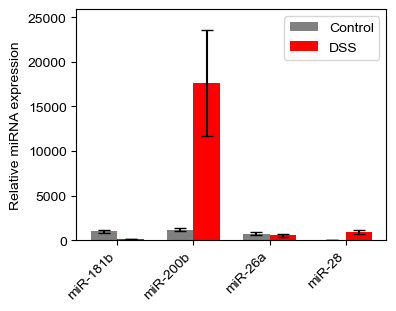

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm


fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=10)
print("aaa")
# Example DataFrame setup
# df = pd.read_csv("your_file.csv")
# df.columns = ["gene", "a", "b", "c", "d", "e", "f"]


dss_cols = [ "SRR18078869", "SRR18078868", "SRR18078867"]
con_cols = ["SRR18078872", "SRR18078871", "SRR18078870"]


df['DSS_mean'] = df[dss_cols].mean(axis=1)
df['DSS_sem'] = df[dss_cols].sem(axis=1)
df['CON_mean'] = df[con_cols].mean(axis=1)
df['CON_sem'] = df[con_cols].sem(axis=1)


x = np.arange(len(df))  
width = 0.35

plt.figure(figsize=(4, 3))
plt.bar(x - width/2, df['CON_mean'], width, yerr=df['CON_sem'], label='Control', color='gray', capsize=4)
plt.bar(x + width/2, df['DSS_mean'], width, yerr=df['DSS_sem'], label='DSS', color='red', capsize=4)
y_max = (df['DSS_mean'] + df['DSS_sem']).max()
plt.ylim(0, y_max * 1.1)

plt.xticks(x, df['gene_name'], rotation=45, ha='right')
plt.ylabel("Relative miRNA expression",fontproperties=arial_font)
# plt.title("Expression in Extracellular Vesicles")

plt.legend(prop=arial_font)

plt.xticks(fontproperties=arial_font)
plt.yticks(fontproperties=arial_font)

plt.grid(True, color="lightgray", linewidth=0.)

# plt.show()
plt.savefig("supp_figureX_D.pdf", format="pdf", bbox_inches="tight")

